In [37]:
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path

from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report,
    roc_curve,
    precision_recall_curve,
    ConfusionMatrixDisplay,
)
from sklearn.calibration import calibration_curve
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

In [38]:
PROJECT_ROOT = Path("..")

PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"

MODELS_DIR = PROJECT_ROOT / "models"

REPORTS_DIR = PROJECT_ROOT / "reports"

MODELS_DIR.mkdir(parents=True, exist_ok=True)

REPORTS_DIR.mkdir(parents=True, exist_ok=True)

In [39]:
X_train = pd.read_csv(PROCESSED_DIR / "X_train_raw_baseline.csv")

X_test = pd.read_csv(PROCESSED_DIR / "X_test_raw_baseline.csv")

y_train = pd.read_csv(PROCESSED_DIR / "y_train.csv").squeeze("columns")

y_test = pd.read_csv(PROCESSED_DIR / "y_test.csv").squeeze("columns")

In [40]:
print("X_train:", X_train.shape)
print("X_test :", X_test.shape)
print("y_train:", y_train.shape)
print("y_test :", y_test.shape)

X_train: (54533, 11)
X_test : (13634, 11)
y_train: (54533,)
y_test : (13634,)


In [41]:
print("Training target:")
print(y_train.value_counts())

print("\nTest target:")
print(y_test.value_counts())

Training target:
cardio
0    27610
1    26923
Name: count, dtype: int64

Test target:
cardio
0    6903
1    6731
Name: count, dtype: int64


In [42]:
print("\nTraining percentage:")
print(y_train.value_counts(normalize=True).mul(100))

print("\nTest percentage:")
print(y_test.value_counts(normalize=True).mul(100))


Training percentage:
cardio
0    50.629894
1    49.370106
Name: proportion, dtype: float64

Test percentage:
cardio
0    50.630776
1    49.369224
Name: proportion, dtype: float64


In [43]:
print("Missing values in X_train:", X_train.isna().sum().sum())

print("Missing values in X_test:", X_test.isna().sum().sum())

Missing values in X_train: 0
Missing values in X_test: 0


In [ ]:
BASELINE_NUMERICAL = ["age_years", "height", "weight", "ap_hi", "ap_lo"]

BASELINE_CATEGORICAL = ["gender", "cholesterol", "gluc", "smoke", "alco", "active"]

In [ ]:
preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            StandardScaler(),
            BASELINE_NUMERICAL,
        ),
        (
            "cat",
            OneHotEncoder(handle_unknown="ignore", sparse_output=False),
            BASELINE_CATEGORICAL,
        ),
    ]
)

In [ ]:
baseline_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", LogisticRegression(max_iter=1000, random_state=42)),
    ]
)

In [47]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

In [48]:
scoring = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc",
    "pr_auc": "average_precision",
}

In [ ]:
cv_results = cross_validate(
    baseline_model,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=-1,
    return_train_score=False,
)

In [ ]:
cv_summary = pd.DataFrame(
    {
        "metric": scoring.keys(),
        "mean": [cv_results[f"test_{metric}"].mean() for metric in scoring],
        "std": [cv_results[f"test_{metric}"].std() for metric in scoring],
    }
)

cv_summary

,metric,mean,std
0,accuracy,0.726569,0.003182
1,precision,0.753704,0.003163
2,recall,0.662742,0.006982
3,f1,0.705282,0.004395
4,roc_auc,0.790517,0.003581
5,pr_auc,0.770050,0.004898


In [51]:
for metric in scoring:
    values = cv_results[f"test_{metric}"]

    print(f"{metric:10s}: " f"{values.mean():.4f} ± {values.std():.4f}")

accuracy  : 0.7266 ± 0.0032
precision : 0.7537 ± 0.0032
recall    : 0.6627 ± 0.0070
f1        : 0.7053 ± 0.0044
roc_auc   : 0.7905 ± 0.0036
pr_auc    : 0.7701 ± 0.0049


In [52]:
baseline_model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](11,)","['age_years','gender','height',...,'smoke','alco','active']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,11
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaini

In [53]:
y_pred = baseline_model.predict(X_test)

y_prob = baseline_model.predict_proba(X_test)[:, 1]

In [54]:
test_metrics = {
    "accuracy": accuracy_score(y_test, y_pred),
    "precision": precision_score(y_test, y_pred),
    "recall": recall_score(y_test, y_pred),
    "f1": f1_score(y_test, y_pred),
    "roc_auc": roc_auc_score(y_test, y_prob),
    "pr_auc": average_precision_score(y_test, y_prob),
}

In [55]:
for metric, value in test_metrics.items():
    print(f"{metric:10s}: {value:.4f}")

accuracy  : 0.7313
precision : 0.7604
recall    : 0.6653
f1        : 0.7097
roc_auc   : 0.7938
pr_auc    : 0.7736


In [ ]:
print(
    classification_report(
        y_test,
        y_pred,
        target_names=["No cardiovascular disease", "Cardiovascular disease"],
    )
)

                           precision    recall  f1-score   support

No cardiovascular disease       0.71      0.80      0.75      6903
   Cardiovascular disease       0.76      0.67      0.71      6731

                 accuracy                           0.73     13634
                macro avg       0.73      0.73      0.73     13634
             weighted avg       0.73      0.73      0.73     13634



In [57]:
cm = confusion_matrix(y_test, y_pred)

print(cm)

[[5492 1411]
 [2253 4478]]


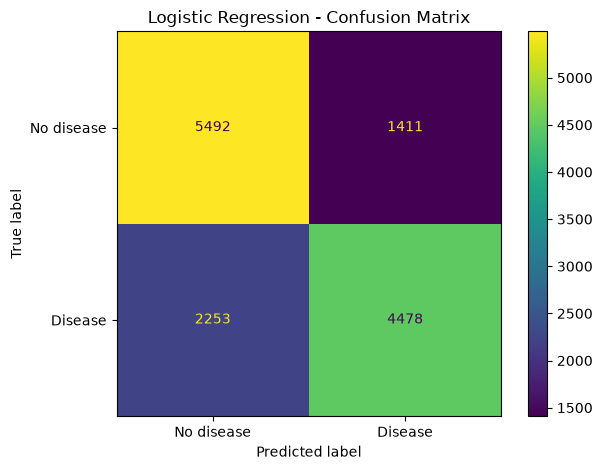

In [58]:
ConfusionMatrixDisplay(
    confusion_matrix=cm, display_labels=["No disease", "Disease"]
).plot()

plt.title("Logistic Regression - Confusion Matrix")
plt.tight_layout()
plt.show()

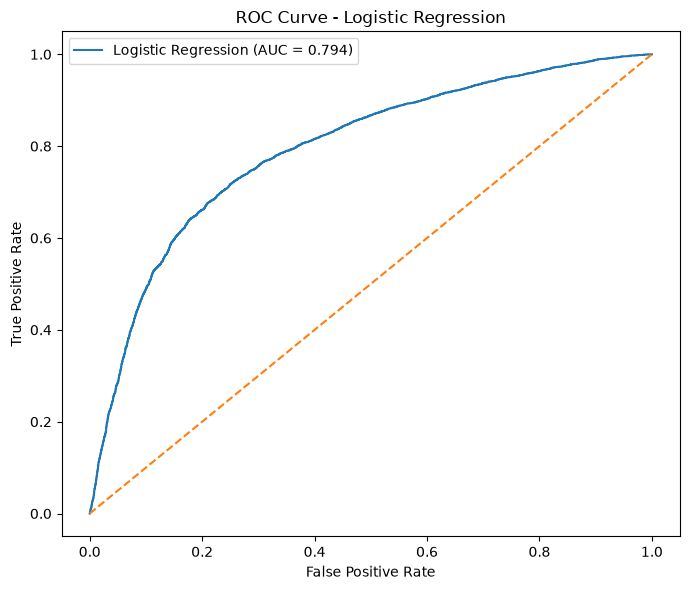

In [59]:
fpr, tpr, thresholds = roc_curve(y_test, y_prob)

roc_auc = roc_auc_score(y_test, y_prob)

plt.figure(figsize=(7, 6))

plt.plot(fpr, tpr, label=f"Logistic Regression (AUC = {roc_auc:.3f})")

plt.plot([0, 1], [0, 1], linestyle="--")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Logistic Regression")
plt.legend()
plt.tight_layout()
plt.show()

In [60]:
prob_true, prob_pred = calibration_curve(y_test, y_prob, n_bins=10, strategy="quantile")

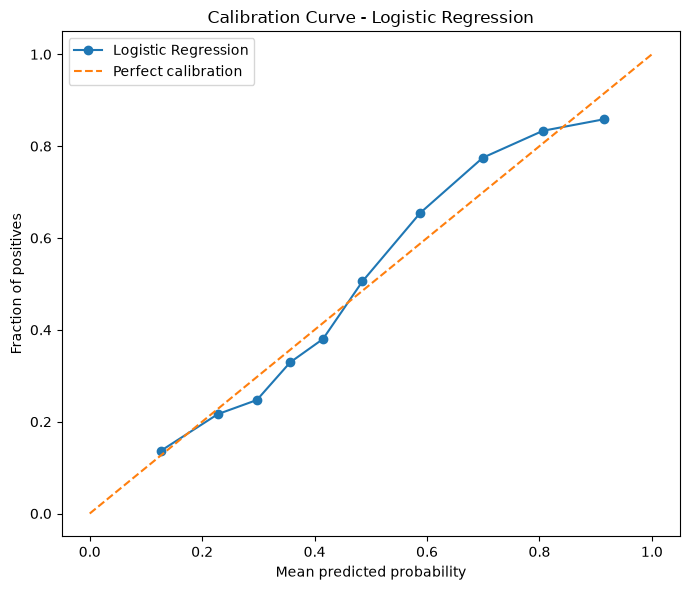

In [61]:
plt.figure(figsize=(7, 6))

plt.plot(prob_pred, prob_true, marker="o", label="Logistic Regression")

plt.plot([0, 1], [0, 1], linestyle="--", label="Perfect calibration")

plt.xlabel("Mean predicted probability")
plt.ylabel("Fraction of positives")
plt.title("Calibration Curve - Logistic Regression")
plt.legend()
plt.tight_layout()
plt.show()

In [ ]:
classifier = baseline_model.named_steps["classifier"]

feature_names = baseline_model.named_steps["preprocessor"].get_feature_names_out()

coefficients = pd.DataFrame(
    {"feature": feature_names, "coefficient": classifier.coef_[0]}
)

In [63]:
coefficients = coefficients.sort_values("coefficient", ascending=False)

coefficients

,feature,coefficient
3,num__ap_hi,0.929590
9,cat__cholesterol_3,0.594625
0,num__age_years,0.342802
15,cat__alco_0,0.149747
2,num__weight,0.141009
17,cat__active_0,0.127348
11,cat__gluc_2,0.126268
10,cat__gluc_1,0.120687
4,num__ap_lo,0.104552
13,cat__smoke_0,0.081914


In [64]:
print("Largest positive coefficients:")
print(coefficients.head(10).to_string(index=False))

print("\nLargest negative coefficients:")
print(coefficients.tail(10).sort_values("coefficient").to_string(index=False))

Largest positive coefficients:
           feature  coefficient
        num__ap_hi     0.929590
cat__cholesterol_3     0.594625
    num__age_years     0.342802
       cat__alco_0     0.149747
       num__weight     0.141009
     cat__active_0     0.127348
       cat__gluc_2     0.126268
       cat__gluc_1     0.120687
        num__ap_lo     0.104552
      cat__smoke_0     0.081914

Largest negative coefficients:
           feature  coefficient
cat__cholesterol_1    -0.464934
       cat__gluc_3    -0.210777
       cat__alco_1    -0.113568
cat__cholesterol_2    -0.093512
     cat__active_1    -0.091169
      cat__smoke_1    -0.045735
       num__height    -0.032161
     cat__gender_2     0.001111
     cat__gender_1     0.035068
      cat__smoke_0     0.081914


In [65]:
coefficients["odds_ratio"] = np.exp(coefficients["coefficient"])

coefficients.sort_values("odds_ratio", ascending=False).head(15)

,feature,coefficient,odds_ratio
3,num__ap_hi,0.929590,2.533470
9,cat__cholesterol_3,0.594625,1.812352
0,num__age_years,0.342802,1.408890
15,cat__alco_0,0.149747,1.161540
2,num__weight,0.141009,1.151435
17,cat__active_0,0.127348,1.135812
11,cat__gluc_2,0.126268,1.134587
10,cat__gluc_1,0.120687,1.128272
4,num__ap_lo,0.104552,1.110213
13,cat__smoke_0,0.081914,1.085362


In [66]:
coefficients.to_csv(REPORTS_DIR / "logistic_regression_coefficients.csv", index=False)

In [67]:
joblib.dump(baseline_model, MODELS_DIR / "logistic_regression_baseline.joblib")

['../models/logistic_regression_baseline.joblib']

In [ ]:
metrics_output = {
    "cross_validation": {
        metric: {
            "mean": float(cv_results[f"test_{metric}"].mean()),
            "std": float(cv_results[f"test_{metric}"].std()),
        }
        for metric in scoring
    },
    "test": {metric: float(value) for metric, value in test_metrics.items()},
}

In [69]:
with open(REPORTS_DIR / "logistic_regression_metrics.json", "w") as f:
    json.dump(metrics_output, f, indent=4)

In [70]:
predictions = pd.DataFrame(
    {"y_true": y_test.to_numpy(), "y_pred": y_pred, "y_probability": y_prob}
)

predictions.to_csv(REPORTS_DIR / "logistic_regression_predictions.csv", index=False)

In [71]:
print("Logistic Regression Baseline")
print("=" * 35)

print("\nCross-validation:")
for metric in scoring:
    mean = cv_results[f"test_{metric}"].mean()
    std = cv_results[f"test_{metric}"].std()

    print(f"{metric:10s}: " f"{mean:.4f} ± {std:.4f}")

print("\nTest set:")
for metric, value in test_metrics.items():
    print(f"{metric:10s}: {value:.4f}")

Logistic Regression Baseline

Cross-validation:
accuracy  : 0.7266 ± 0.0032
precision : 0.7537 ± 0.0032
recall    : 0.6627 ± 0.0070
f1        : 0.7053 ± 0.0044
roc_auc   : 0.7905 ± 0.0036
pr_auc    : 0.7701 ± 0.0049

Test set:
accuracy  : 0.7313
precision : 0.7604
recall    : 0.6653
f1        : 0.7097
roc_auc   : 0.7938
pr_auc    : 0.7736


In [72]:
print("Model files:")

for path in sorted(MODELS_DIR.iterdir()):
    print(" -", path.name)

print("\nReport files:")

for path in sorted(REPORTS_DIR.iterdir()):
    print(" -", path.name)

Model files:
 - logistic_regression_baseline.joblib

Report files:
 - logistic_regression_coefficients.csv
 - logistic_regression_metrics.json
 - logistic_regression_predictions.csv
